In [ ]:
!pip install -q ucimlrepo

In [ ]:
!pip install -q ucimlrepo

import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

# Download dataset
heart = fetch_ucirepo(id=45)

# Extract features and target
X = heart.data.features.copy()
y = heart.data.targets.iloc[:, 0]

# Convert target into binary classification
y = (y > 0).astype(int)

print("Dataset successfully loaded!")
print("Dataset shape:", X.shape)
print("\nFirst 5 records:")
print(X.head())

print("\nTarget distribution:")
print(y.value_counts())

Dataset successfully loaded!
Dataset shape: (303, 13)

First 5 records:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   
3   37    1   3       130   250    0        0      187      0      3.5      3   
4   41    0   2       130   204    0        2      172      0      1.4      1   

    ca  thal  
0  0.0   6.0  
1  3.0   3.0  
2  2.0   7.0  
3  0.0   3.0  
4  0.0   3.0  

Target distribution:
num
0    164
1    139
Name: count, dtype: int64


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical = [
    'sex', 'cp', 'fbs', 'restecg',
    'exang', 'slope', 'thal'
]

numerical = [
    'age', 'trestbps', 'chol',
    'thalach', 'oldpeak', 'ca'
]

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, numerical),
    ('cat', cat_pipeline, categorical)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create Random Forest model
model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        class_weight='balanced'
    ))
])

# Train model
model.fit(X_train, y_train)

print("MODEL TRAINING COMPLETED!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

MODEL TRAINING COMPLETED!
Training records: 242
Testing records: 61


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Generate predictions
predictions = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, predictions)

print("HEART ANOMALY PREDICTION RESULTS")
print("--------------------------------")
print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))

HEART ANOMALY PREDICTION RESULTS
--------------------------------
Model Accuracy: 88.52 %

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61


Confusion Matrix:
[[28  5]
 [ 2 26]]


In [ ]:
import joblib

joblib.dump(model, "heart_anomaly_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
sample_patient = X_test.iloc[[0]]

prediction = model.predict(sample_patient)[0]
probability = model.predict_proba(sample_patient)[0][1]

print("PATIENT PREDICTION")
print("------------------")
print("Prediction:", "Potential heart disease" if prediction == 1 else "No heart disease detected")
print("Model probability:", round(probability * 100, 2), "%")

PATIENT PREDICTION
------------------
Prediction: No heart disease detected
Model probability: 30.0 %


HEART ANOMALY DETECTION - PERFORMANCE DASHBOARD
Model Accuracy: 88.52%

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



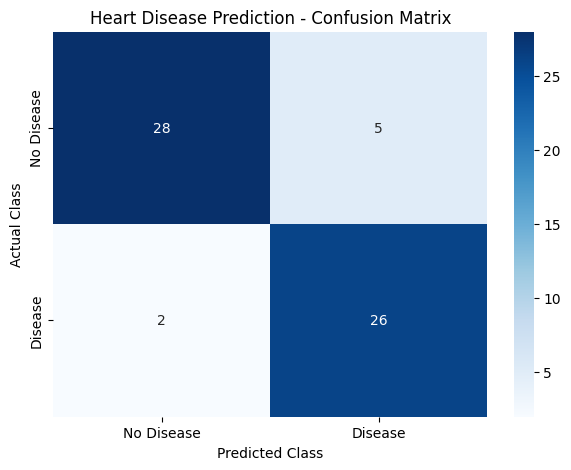

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Predictions
predictions = model.predict(X_test)

# Metrics
accuracy = accuracy_score(y_test, predictions)
cm = confusion_matrix(y_test, predictions)

print("HEART ANOMALY DETECTION - PERFORMANCE DASHBOARD")
print("=" * 50)
print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, predictions))

# Visualise confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Disease', 'Disease'],
    yticklabels=['No Disease', 'Disease']
)

plt.title("Heart Disease Prediction - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

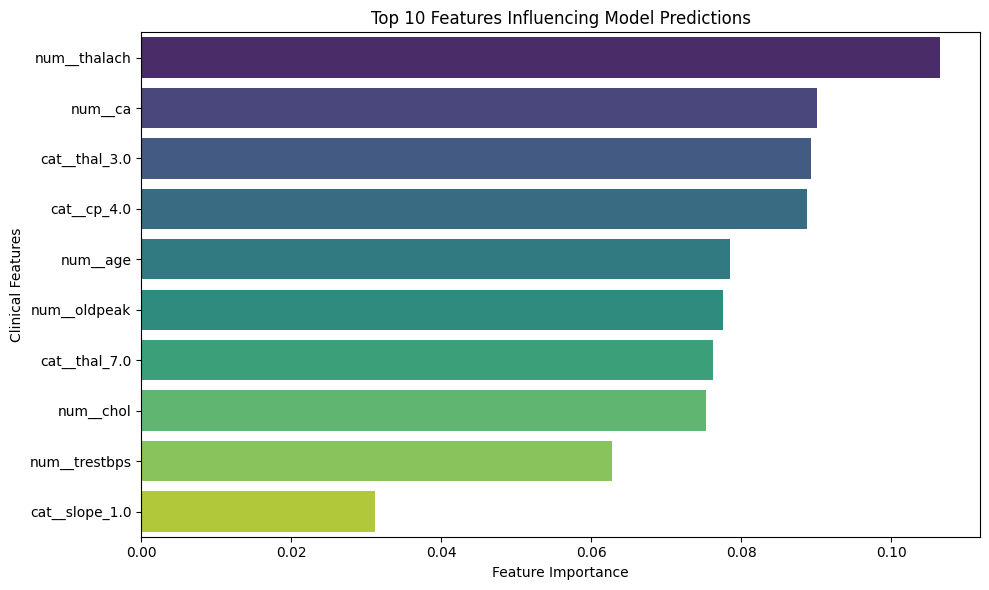

In [ ]:
# Extract trained Random Forest
rf = model.named_steps['classifier']

# Get encoded feature names
feature_names = (
    model.named_steps['preprocessing']
    .get_feature_names_out()
)

# Extract feature importance
importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf.feature_importances_
})

# Sort and display top 10
importance = importance.sort_values(
    by='Importance',
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)

plt.title("Top 10 Features Influencing Model Predictions")
plt.xlabel("Feature Importance")
plt.ylabel("Clinical Features")
plt.tight_layout()
plt.show()

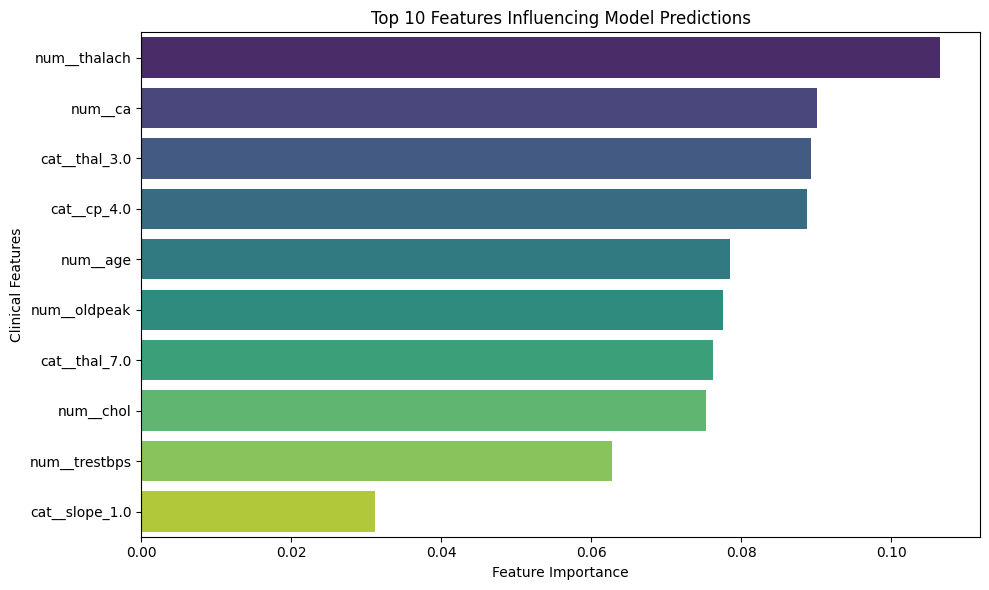

In [ ]:
# Extract trained Random Forest
rf = model.named_steps['classifier']

# Get encoded feature names
feature_names = (
    model.named_steps['preprocessing']
    .get_feature_names_out()
)

# Extract feature importance
importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf.feature_importances_
})

# Sort and display top 10
importance = importance.sort_values(
    by='Importance',
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)

plt.title("Top 10 Features Influencing Model Predictions")
plt.xlabel("Feature Importance")
plt.ylabel("Clinical Features")
plt.tight_layout()
plt.show()

In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr

def predict_heart(age, sex, cp, trestbps, chol,
                  fbs, restecg, thalach, exang,
                  oldpeak, slope, ca, thal):

    patient = pd.DataFrame([{
        'age': age,
        'sex': sex,
        'cp': cp,
        'trestbps': trestbps,
        'chol': chol,
        'fbs': fbs,
        'restecg': restecg,
        'thalach': thalach,
        'exang': exang,
        'oldpeak': oldpeak,
        'slope': slope,
        'ca': ca,
        'thal': thal
    }])

    prediction = model.predict(patient)[0]
    probability = model.predict_proba(patient)[0][1]

    result = (
        "Potential heart disease pattern detected"
        if prediction == 1
        else "No heart disease pattern detected"
    )

    return result, f"Model score: {probability * 100:.2f}%"

demo = gr.Interface(
    fn=predict_heart,
    inputs=[
        gr.Slider(20, 100, value=45, label="Age"),
        gr.Radio([0, 1], label="Sex (0=Female, 1=Male)"),
        gr.Dropdown([1, 2, 3, 4], label="Chest Pain Type"),
        gr.Slider(80, 220, value=120, label="Resting Blood Pressure"),
        gr.Slider(100, 600, value=200, label="Cholesterol"),
        gr.Radio([0, 1], label="Fasting Blood Sugar > 120 mg/dl"),
        gr.Dropdown([0, 1, 2], label="Resting ECG"),
        gr.Slider(60, 220, value=150, label="Maximum Heart Rate"),
        gr.Radio([0, 1], label="Exercise Induced Angina"),
        gr.Slider(0, 6, value=1, label="ST Depression"),
        gr.Dropdown([1, 2, 3], label="ST Slope"),
        gr.Slider(0, 3, value=0, step=1, label="Major Vessels"),
        gr.Dropdown([3, 6, 7], label="Thalassemia")
    ],
    outputs=[
        gr.Textbox(label="Prediction"),
        gr.Textbox(label="Model Probability")
    ],
    title="❤️ Heart Anomaly Prediction System",
    description="Machine Learning Based Heart Disease Classification | Random Forest"
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c352f25afbbe1698c5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
print("HEART ANOMALY PROJECT - DIAGNOSTICS")
print("=" * 45)

variables = [
    'X',
    'y',
    'preprocessor',
    'X_train',
    'X_test',
    'y_train',
    'y_test',
    'model'
]

for var in variables:
    if var in globals():
        print(f"{var}: EXISTS")
    else:
        print(f"{var}: MISSING")

HEART ANOMALY PROJECT - DIAGNOSTICS
X: EXISTS
y: EXISTS
preprocessor: EXISTS
X_train: EXISTS
X_test: EXISTS
y_train: EXISTS
y_test: EXISTS
model: EXISTS


In [ ]:
print("DATASET CHECK")
print("=" * 35)

if 'X' in globals() and 'y' in globals():
    print("Feature shape:", X.shape)
    print("Target shape:", y.shape)

    print("\nFirst 5 patient records:")
    print(X.head())

    print("\nTarget distribution:")
    print(y.value_counts())
else:
    print("Dataset is missing. Load the dataset first.")

DATASET CHECK
Feature shape: (303, 13)
Target shape: (303,)

First 5 patient records:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   
3   37    1   3       130   250    0        0      187      0      3.5      3   
4   41    0   2       130   204    0        2      172      0      1.4      1   

    ca  thal  
0  0.0   6.0  
1  3.0   3.0  
2  2.0   7.0  
3  0.0   3.0  
4  0.0   3.0  

Target distribution:
num
0    164
1    139
Name: count, dtype: int64


In [ ]:
print("MODEL STATUS")
print("=" * 35)

if 'model' in globals():
    try:
        print("Model steps:", list(model.named_steps.keys()))

        if 'X_test' in globals() and 'y_test' in globals():
            predictions = model.predict(X_test)
            print("Prediction test: PASSED")
            print("Test records:", len(X_test))
            print("Predictions generated:", len(predictions))
        else:
            print("Testing data is missing.")

    except Exception as e:
        print("Model check failed:", repr(e))
else:
    print("Model variable is missing. Train the model first.")

MODEL STATUS
Model steps: ['preprocessing', 'classifier']
Prediction test: PASSED
Test records: 61
Predictions generated: 61
